# CISC7204 Preliminary Project Proposal – Ideation Visualization

**Student:** CHAN CHENG I (MC649355)

**Research Question:** How have average private residential property prices in Hong Kong evolved across different housing classes (A–E) and geographic regions since 1999, and to what extent do these trends reveal widening or narrowing affordability gaps among housing segments?

**Region:** Hong Kong SAR, China | **Domain:** Housing / Real Estate

## Data Sources

1. [RVD Average Prices by Class (Monthly)](http://www.rvd.gov.hk/datagovhk/1.2M.csv)
2. [RVD Price Indices by Class (Territory-wide, Monthly)](http://www.rvd.gov.hk/datagovhk/1.4M.csv)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

BASE = os.path.dirname(os.path.abspath('.')) if os.path.basename(os.getcwd()) != 'Proposal' else os.getcwd()
if not os.path.exists(os.path.join(BASE, 'rvd_price_indices.csv')):
    BASE = os.path.join(BASE, 'Proposal')

%matplotlib inline

In [2]:
# Load price indices dataset
df_idx = pd.read_csv(os.path.join(BASE, 'rvd_price_indices.csv'), skiprows=1)
df_idx = df_idx.rename(columns={'Month': 'month'})
df_idx['date'] = pd.to_datetime(df_idx['month'], format='%m-%Y')
df_idx = df_idx.sort_values('date')
df_idx.head()

,month,Class A,Class A - Remarks,Class B,Class B - Remarks,Class C,Class C - Remarks,Class D,Class D - Remarks,Class E,Class E - Remarks,"Classes A, B & C","Classes A, B & C - Remarks",Classes D & E,Classes D & E - Remarks,All Classes,All Classes - Remarks,date
0,01-1993,90.4,NaN,81.3,NaN,80.7,NaN,74.2,NaN,58.1,NaN,85.5,NaN,69.6,NaN,84.4,NaN,1993-01-01
1,02-1993,90.5,NaN,82.6,NaN,81.3,NaN,74.9,NaN,62.2,NaN,86.2,NaN,71.3,NaN,85.2,NaN,1993-02-01
2,03-1993,90.2,NaN,83.9,NaN,81.9,NaN,75.4,NaN,64.6,NaN,86.7,NaN,72.4,NaN,85.7,NaN,1993-03-01
3,04-1993,92.5,NaN,85.4,NaN,83.7,NaN,76.8,NaN,66.2,NaN,88.5,NaN,73.9,NaN,87.5,NaN,1993-04-01
4,05-1993,95.9,NaN,88.6,NaN,85.9,NaN,80.5,NaN,72.3,NaN,91.6,NaN,78.2,NaN,90.7,NaN,1993-05-01


In [3]:
# Load average prices by region dataset
df_price = pd.read_csv(os.path.join(BASE, 'rvd_prices.csv'), skiprows=1)
df_price = df_price.rename(columns={'Month': 'month'})
df_price['date'] = pd.to_datetime(df_price['month'], format='%m-%Y')
df_price = df_price.sort_values('date')
df_price.head()

,month,Class A Hong Kong,Class A Hong Kong - Remarks,Class A Kowloon,Class A Kowloon - Remarks,Class A New Territories,Class A New Territories - Remarks,Class B Hong Kong,Class B Hong Kong - Remarks,Class B Kowloon,...,Class D Kowloon - Remarks,Class D New Territories,Class D New Territories - Remarks,Class E Hong Kong,Class E Hong Kong - Remarks,Class E Kowloon,Class E Kowloon - Remarks,Class E New Territories,Class E New Territories - Remarks,date
0,01-1999,42663,NaN,36842,NaN,36679,NaN,50141,NaN,37945,...,NaN,50457,NaN,72978,NaN,62551,Z,50968,NaN,1999-01-01
1,02-1999,43068,NaN,35834,NaN,36802,NaN,47950,NaN,38428,...,NaN,46759,NaN,66326,NaN,59774,Z,45945,NaN,1999-02-01
2,03-1999,42683,NaN,36731,NaN,36992,NaN,51060,NaN,38254,...,NaN,50737,NaN,74608,NaN,61790,Z,46120,NaN,1999-03-01
3,04-1999,43223,NaN,36543,NaN,36485,NaN,50189,NaN,39445,...,NaN,43915,NaN,73489,NaN,75745,Z,46953,Z,1999-04-01
4,05-1999,43316,NaN,36449,NaN,38035,NaN,50650,NaN,37945,...,NaN,48495,NaN,78077,NaN,86018,Z,50454,NaN,1999-05-01


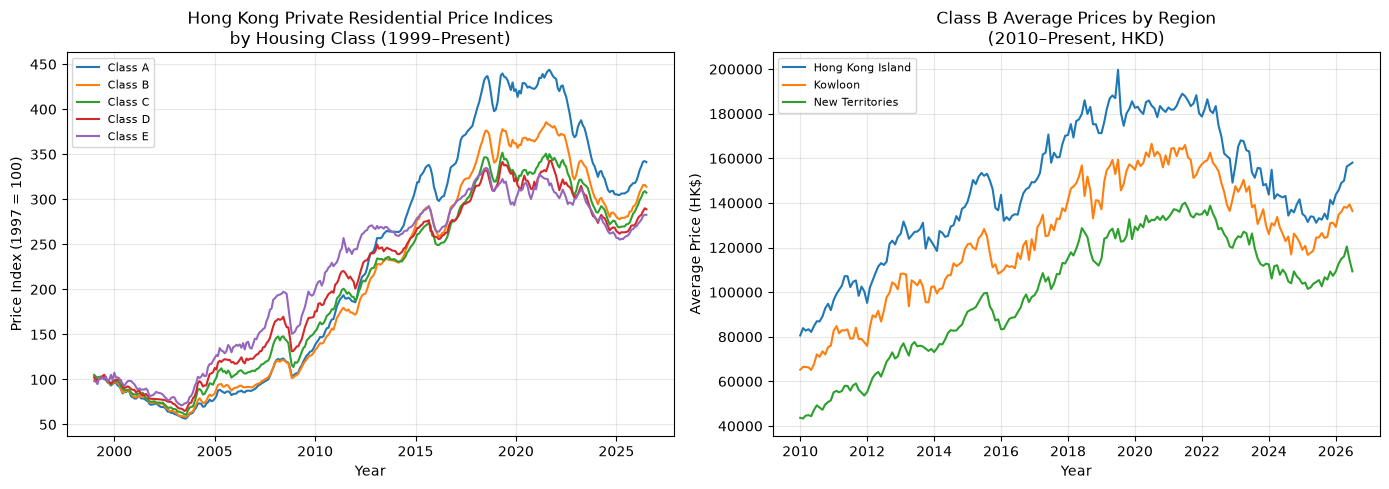

In [4]:
classes = ['Class A', 'Class B', 'Class C', 'Class D', 'Class E']
df_recent = df_idx[df_idx['date'] >= '1999-01-01'].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Territory-wide price indices by housing class
ax1 = axes[0]
for cls in classes:
    ax1.plot(df_recent['date'], df_recent[cls], label=cls, linewidth=1.5)
ax1.set_title('Hong Kong Private Residential Price Indices\nby Housing Class (1999–Present)')
ax1.set_xlabel('Year')
ax1.set_ylabel('Price Index (1999 = 100)')
ax1.legend(loc='upper left', fontsize=8)
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.grid(True, alpha=0.3)

# Chart 2: Class B average prices by region
df_price_recent = df_price[df_price['date'] >= '2010-01-01'].copy()
ax2 = axes[1]
regions = {
    'Class B Hong Kong': 'Hong Kong Island',
    'Class B Kowloon': 'Kowloon',
    'Class B New Territories': 'New Territories',
}
for col, label in regions.items():
    series = pd.to_numeric(df_price_recent[col], errors='coerce')
    ax2.plot(df_price_recent['date'], series, label=label, linewidth=1.5)
ax2.set_title('Class B Average Prices by Region\n(2010–Present, HK$/m²)')
ax2.set_xlabel('Year')
ax2.set_ylabel('Average Price (HK$/m²)')
ax2.legend(loc='upper left', fontsize=8)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(BASE, 'proposal_visualization.png'), dpi=150, bbox_inches='tight')
plt.show()

## Visualization Justification

The left panel plots territory-wide price indices for housing Classes A through E from 1999 to the present. This directly addresses the research question by revealing whether affordability gaps across housing segments are widening: if lower-class units (A, B) appreciate faster than luxury units (D, E), the lines will diverge over time.

The right panel compares Class B average prices across Hong Kong Island, Kowloon, and the New Territories, highlighting persistent regional disparities. Together, these charts provide preliminary evidence that both housing class and geography are key dimensions of Hong Kong's property market dynamics, motivating deeper statistical analysis in the full project.